# 2D axial slice extraction

This example shows how to convert registered 3D medical images into 2D axial slices to train a 2D model.

The extraction strategy depends on the purpose of the dataset. In this notebook, we consider two common situations:

1. **Training on image content.**  
   We extract axial slices regularly from each 3D volume while discarding slices located at the inferior and superior borders. These border slices contain background.

2. **Working only with abnormal slices.**  
   When an anomaly mask is available, we first extract the axial indices that contain abnormal voxels. We store these indices in a TSV file and then use this file to extract exactly the corresponding image slices.


## 1. Setup and dataset

We first import the required components for the example:

- `BidsStrokeSmall` is a small BIDS-formatted stroke dataset;
- `TransformsHandler` combines extraction and preprocessing operations;
- `Slice` extracts 2D slices from a 3D volume;
- `TorchIO` is used here for intensity rescaling and spatial resizing;
- `pandas` and `Path` are used later to construct the TSV file that defines anomaly-containing slice indices.

In [68]:
import torch
import pandas as pd
from pathlib import Path
# Dataset
from clinicadl.data.datasets.examples import BidsStrokeSmall
# Transforms
from clinicadl.transforms import TransformsHandler
from clinicadl.transforms.extraction import Slice, Image
import torchio as tio

# Dataloader

## 2. Strategy A: Training extraction

### Objective

For a training dataset, we generally want to retain slices containing useful anatomy while avoiding slices that contain almost only background. Because the volumes considered here are registered to a common spatial space (for example the MNI space), the anatomical field of view is consistent across subjects. Thus, we can apply a simple fixed rule: remove a predefined number of slices from the beginning and end of the axial direction, then use all remaining slices. In this example, we discard the first and last 20 axial slices.

### What we will do

We will:

1. load one original 3D volume and inspect it;
2. define a `Slice` extractor along the axial direction;
3. exclude 20 slices at each border;
4. rescale image intensities to `[-1, 1]`;
5. resize each extracted slice to `128 × 128`;
6. create the transformed dataset;
7. check the resulting number of 2D samples and visualize representative slices.

This extraction rule is appropriate here because the images are registered. For non-registered datasets, a fixed border exclusion would not necessarily remove the same anatomical regions for every subject.


### 2.1 Inspect an original 3D volume

Before introducing any extraction transform, we load the dataset in its original volumetric form. We then plot the volume to verify the border slices to discard. 

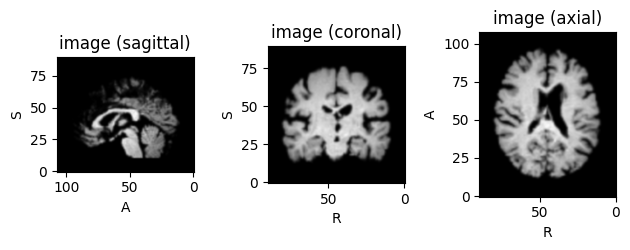

In [69]:
# Load the original dataset without lesion masks.
# At this stage, each dataset item corresponds to a 3D image volume.
bids = BidsStrokeSmall(
    columns=["age"],
    masks=False,
)

# Inspect one subject before applying any slice extraction.
sample = bids[0]
sample.plot()


### 2.2 Define the slice extraction and preprocessing pipeline

The extraction is performed along `slice_direction=2`, corresponding here to the axial dimension.

The `borders=(20, 20)` argument removes 20 slices from each end of the volume before generating the 2D samples. 

- Before extraction, the intensity rescaling is applied: **Intensity rescaling:** each image is intensity rescaled to the interval `[-1, 1]`;
- After extraction, the spatial resizing is applied: **Spatial resizing:** each slice is resized to `128 × 128`.


In [70]:
transform = TransformsHandler(
    # Convert each 3D volume into axial 2D slices.
    extraction=Slice(
        borders=(20, 20),   # Discard inferior and superior background slices.
        slice_direction=2,  # Axial direction.
    ),

    # Applied to the image intensities before extraction.
    image_transforms=[
        tio.RescaleIntensity(
            out_min_max=[-1, 1],
        )
    ],

    # Applied after extraction.
    sample_transforms=[
        tio.Resize((128, 128, 1)),
    ],
)

# Recreate the dataset with the extraction pipeline.
# Each item now corresponds to one extracted 2D slice rather than one 3D volume.
bids = BidsStrokeSmall(
    columns=["age"],
    masks=False,
    transforms=transform,
)


### 2.3 Check the extracted dataset

After slice extraction, `len(bids)` no longer represents the number of 3D subjects or sessions. It represents the total number of **2D slices generated by the extraction pipeline**.

This is an important distinction when constructing dataloaders: the effective training dataset is now indexed at the slice level.


In [71]:
len(bids)

Counting the number of samples per image: 10images [00:02,  3.53images/s]


500

### 2.4 Visualize extracted slices

We inspect two samples at different positions in the transformed dataset. This verifies three properties of the preprocessing:

- the extracted samples contain anatomical information rather than only background;
- the spatial size is consistent;
- the intensity rescaling and orientation are suitable for subsequent model input.

`torch.rot90` is used only for visualization and does not modify the stored dataset.


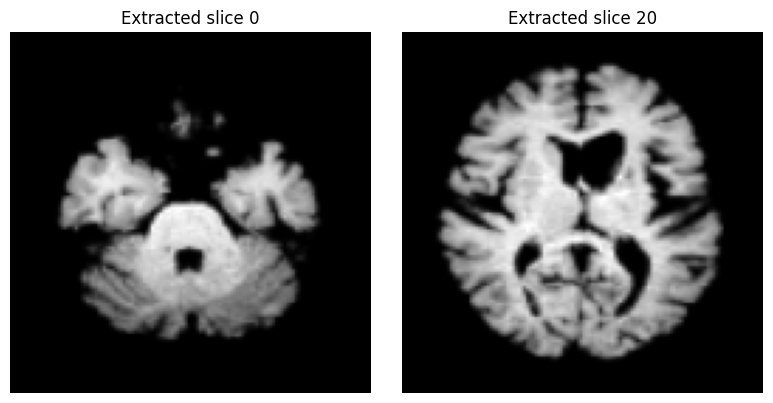

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sample_1 = bids[0]
sample_2 = bids[20]

tensor_1 = sample_1["image"].data.squeeze()
tensor_2 = sample_2["image"].data.squeeze()

axes[0].imshow(torch.rot90(tensor_1), cmap="gray")
axes[0].set_title("Extracted slice 0")
axes[0].axis("off")

axes[1].imshow(torch.rot90(tensor_2), cmap="gray")
axes[1].set_title("Extracted slice 20")
axes[1].axis("off")

plt.tight_layout()


## 3. Strategy B: extract only slices containing an anomaly

### Goal

For evaluation using every slice of a volume may be unnecessary. Instead, we may want to retain only the axial slices in which the lesion mask contains at least one abnormal voxel.

The extraction proceeds in two stages:

1. **Identify the relevant slice indices from the 3D lesion masks.**
2. **Use those indices to contruct the slice extraction.**

The intermediate TSV file connects these two stages. Each row identifies a subject/session and one axial slice that contains an anomaly.

In addition to the slice index, we record:

- `slice_anomaly_size`: number of abnormal voxels in that slice;
- `total_anomaly_size`: total number of abnormal voxels in the complete 3D mask.


We first download the dataset and look at the 3D volumes. We extract also the mask related to the anomaly. In this section we are interested of extracting only slices for wich we have an anomaly. We are going to first extract this indexes. We will create a tsv that contains all the slices. 

### 3.1 Reload the volumetric dataset with lesion masks

We return to the original 3D representation and enable the lesion masks. We perform the slice index search **before** applying any 2D extraction.

In [73]:
# Reload the original 3D dataset, this time including lesion masks.
bids = BidsStrokeSmall(
    columns=["age"],
    masks=True,
)


### 3.2 Inspect an image-mask pair

We visualize one sample to verify that the lesion mask is correctly associated with the image volume.


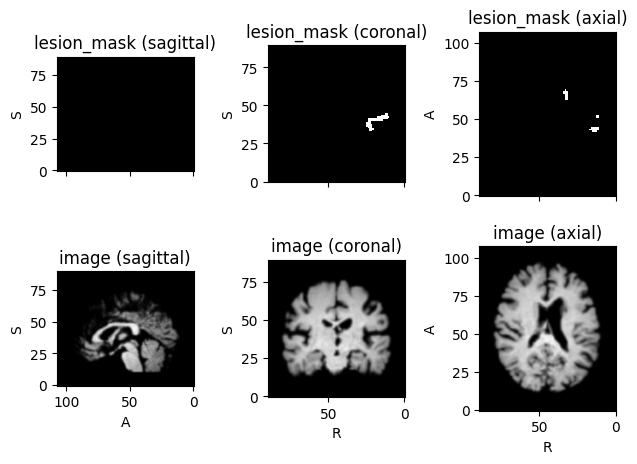

In [74]:
sample =  bids[0]
sample.plot()

### 3.3 Find every axial slice containing abnormal voxels

For each 3D sample, we:

1. retrieve the participant and session identifiers;
2. load the lesion mask as an integer tensor;
3. verify that the mask is three-dimensional;
4. count non-zero mask voxels independently for each axial slice;
5. compute the total lesion size in the complete volume;
6. keep only slice indices whose abnormal-voxel count is strictly positive;
7. store one record per abnormal slice.

The resulting table therefore contains a variable number of rows per subject: subjects with lesions extending over many axial slices contribute more rows.

The lesion mask is reduced over dimensions `(0, 1)`. Consequently, the remaining dimension corresponds to the slice index used by `slice_direction=2`.


In [75]:
records = []

for i in range(len(bids)):

        # Extract sample
        sample = bids[i]

        participant_id = sample["participant_id"]
        session_id = sample["session_id"]

        lesion_mask = (
            sample["lesion_mask"]
            .data
            .squeeze()
            .to(torch.int64)
        ) # Ensure int

        if lesion_mask.ndim != 3:
            raise ValueError(
                f"Unexpected mask shape: "
                f"{lesion_mask.shape}"
            )
        
        slice_counts = torch.count_nonzero(
            lesion_mask,
            dim=(0, 1),
        ).cpu().numpy()

        total_anomaly_size = int(
            slice_counts.sum()
        )

        # ---------------------------------------------------------
        # Store anomalous slices
        # ---------------------------------------------------------

        for slice_index, count in enumerate(
            slice_counts
        ):

            if count == 0:
                continue

            records.append(
                {
                    "participant_id": participant_id,
                    "session_id": session_id,
                    "slice_idx": slice_index,
                    "slice_anomaly_size": int(count),
                    "total_anomaly_size": (
                        total_anomaly_size
                    ),
                }
            )


df = pd.DataFrame(records)

if df.empty:
    print("No anomalies found.")


df.to_csv(
    "tmp/stroke_anomalies_slices.tsv",
    sep="\t",
    index=False,
)

print(
    f"Saved {len(df)} anomalous slices "
    "to anomalies_slices.tsv"
)


print(df)

Saved 189 anomalous slices to anomalies_slices.tsv
    participant_id session_id  slice_idx  slice_anomaly_size  \
0          sub-002   ses-M000         26                   2   
1          sub-002   ses-M000         27                   6   
2          sub-002   ses-M000         28                  13   
3          sub-002   ses-M000         29                  20   
4          sub-002   ses-M000         30                  32   
..             ...        ...        ...                 ...   
184        sub-099   ses-M000         62                  18   
185        sub-099   ses-M000         63                  10   
186        sub-099   ses-M000         64                   7   
187        sub-099   ses-M000         65                   4   
188        sub-099   ses-M000         66                   2   

     total_anomaly_size  
0                  1548  
1                  1548  
2                  1548  
3                  1548  
4                  1548  
..                  ... 

### 3.4 Build an extractor from the TSV file

The TSV file now acts as an explicit slice-selection map.

Instead of asking `Slice` to retain a regular range of indices, we provide `tsv_path`. The extractor can then retrieve the exact axial slice associated with each participant/session entry in the table.

This mechanism is useful whenever slice selection depends on subject-specific information, such as:

- lesion presence;
- lesion size;
- anatomical annotations;
- manually selected indices;
- another preprocessing or quality-control criterion.


In [76]:
extraction_from_tsv = Slice(
                slice_direction=2,
                tsv_path = Path("tmp/stroke_anomalies_slices.tsv")
            )

### 3.5 Apply the same preprocessing to the selected abnormal slices

We now combine the TSV-driven extraction with the same image preprocessing used previously:

- intensities are rescaled to `[-1, 1]`;
- slices are resized to `128 × 128`.

Only the extraction rule changes. This separation is useful because the spatial/intensity preprocessing can remain identical across training and evaluation datasets while the slice-selection policy is adapted to each use case.


In [77]:
transform = TransformsHandler(
            extraction = extraction_from_tsv,
            image_transforms=[
                tio.RescaleIntensity(
                    out_min_max=[-1,1],
                )
            ],
            sample_transforms=[
                tio.Resize((128, 128, 1)),
            ],
        )

### 3.6 Create the anomaly-focused 2D dataset

We instantiate the dataset again with the new transform. Each resulting item now corresponds to one of the subject-specific slice indices stored in the TSV file. The expected dataset length is the number of selected TSV rows, assuming that every row can be matched to a valid dataset sample.


In [78]:
bids = BidsStrokeSmall(transforms = transform)

In [79]:
len(bids)

Counting the number of samples per image: 10images [00:04,  2.16images/s]


189

### 3.7 Verify the extracted image and lesion mask

Finally, we inspect one selected sample and display the image next to its lesion mask.

This final check serves two purposes:

1. verify that the TSV-driven extractor selected a slice that actually contains a lesion;
2. verify that the image and mask remain spatially aligned after extraction and resizing.

A successful result should show non-zero lesion pixels in the mask and a corresponding anatomical location in the image.


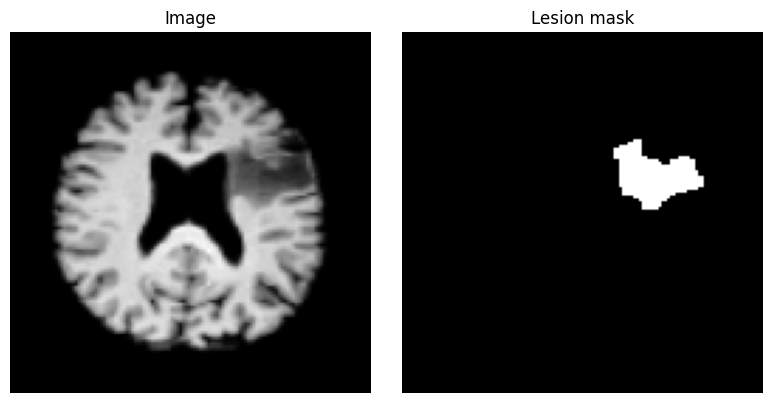

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sample = bids[70]

lesion_mask = sample["lesion_mask"].data.squeeze()
image = sample["image"].data.squeeze()

axes[0].imshow(torch.rot90(image), cmap="gray")
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(torch.rot90(lesion_mask), cmap="gray")
axes[1].set_title("Lesion mask")
axes[1].axis("off")

plt.tight_layout()
